In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.sparse import issparse
from scipy.stats import mannwhitneyu
import scanpy as sc
import tqdm
import functools
import glob
import gzip as gz
import itertools
import math
import os
import sys
from importlib import reload

sys.path.append('/Genomics/pritykinlab/dillon/perturbseq/scripts/utils')
import misc
import clonal_processing

In [9]:
plt.rcParams["axes.titlesize"] = 25
plt.rcParams["axes.labelsize"] = 25
plt.rcParams["xtick.labelsize"] = 20
plt.rcParams["ytick.labelsize"] = 20
plt.rcParams["lines.markersize"] = 5
plt.rcParams['axes.grid'] = False
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True
plt.rcParams['xtick.major.size'] = 5
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['ytick.major.size'] = 5
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['axes.edgecolor'] = 'black'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.title_fontsize'] = 15
plt.rcParams['legend.edgecolor'] = 'dimgray'
plt.rcParams['figure.figsize'] = (7,7)

In [10]:
reload(misc)

<module 'misc' from '/Genomics/pritykinlab/dillon/perturbseq/scripts/utils/misc.py'>

# Initial Processing

In [4]:
# Jupyter Notebook cell

# 1) Define the base directory and lanes
base_dir = "/Genomics/pritykinlab/share/perturbseq/fromMarc/new_data/exp49_CP8_old/cellranger"
lanes = [f"lane{n}" for n in range(1, 9)]

# 2) Load each lane's data into an OrderedDict of AnnData
adata_dict = misc.load_adata_dict(
    base_dir=base_dir,
    lane_list=lanes,
    filename="filtered_feature_bc_matrix.h5",  # typical Cell Ranger output
    mito_prefix="mt-"                          # typical for mouse data
)

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_

##### Lane: lane1 #####


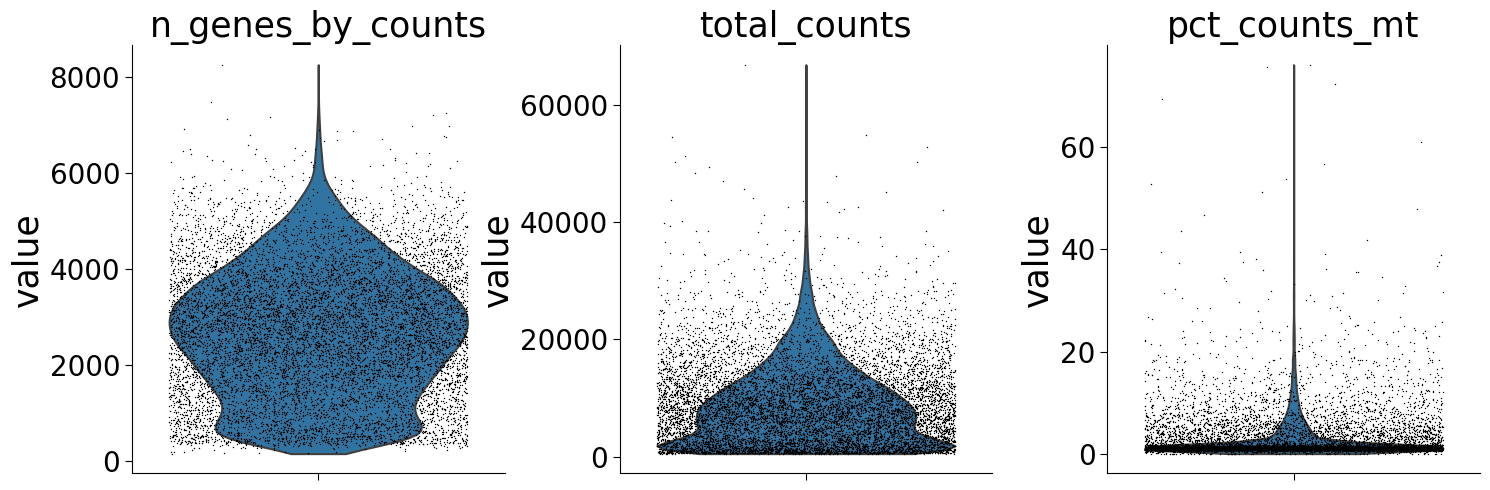

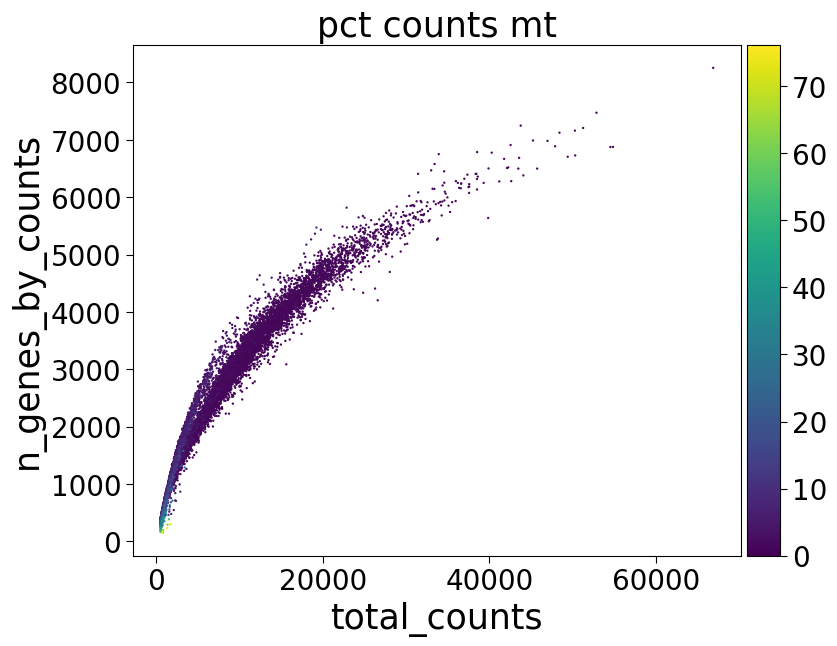

##### Lane: lane2 #####


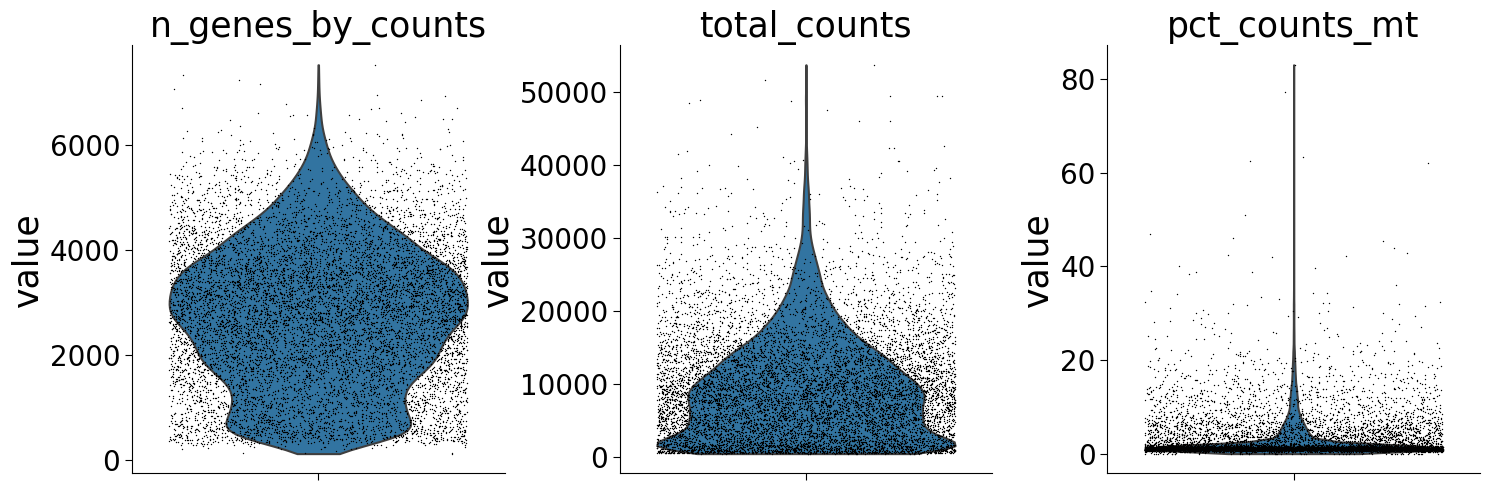

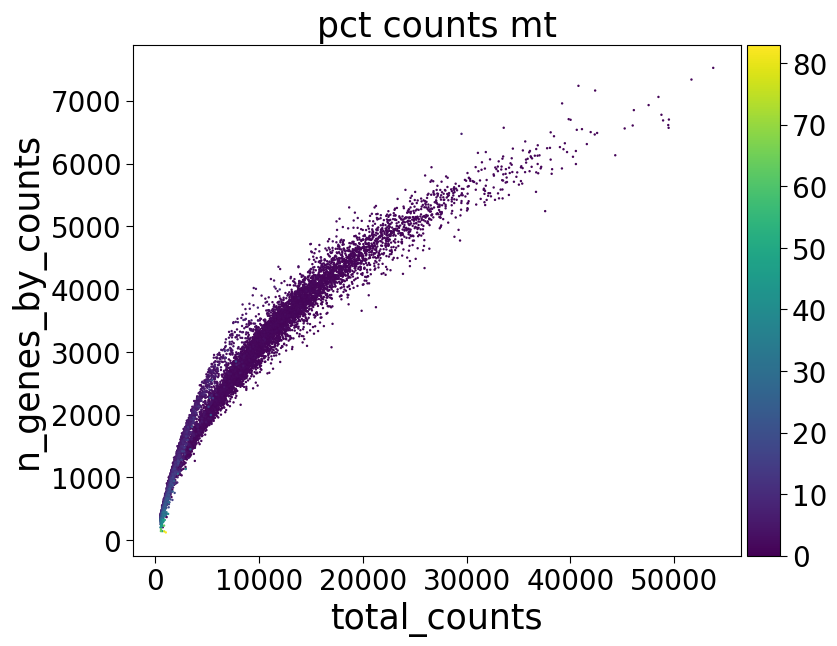

##### Lane: lane3 #####


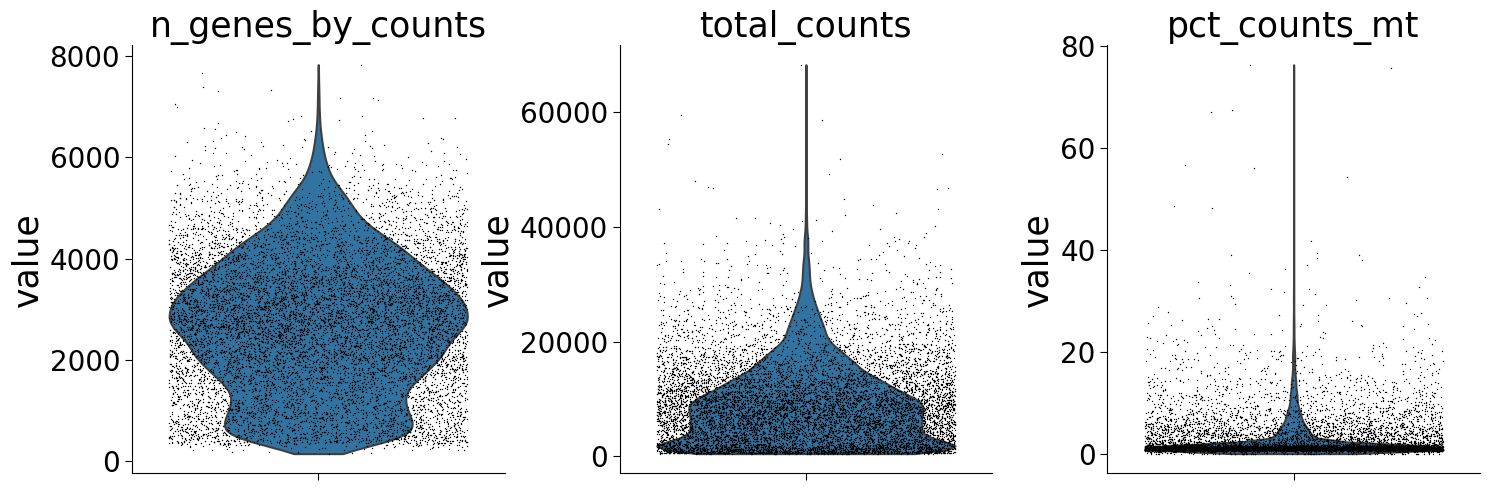

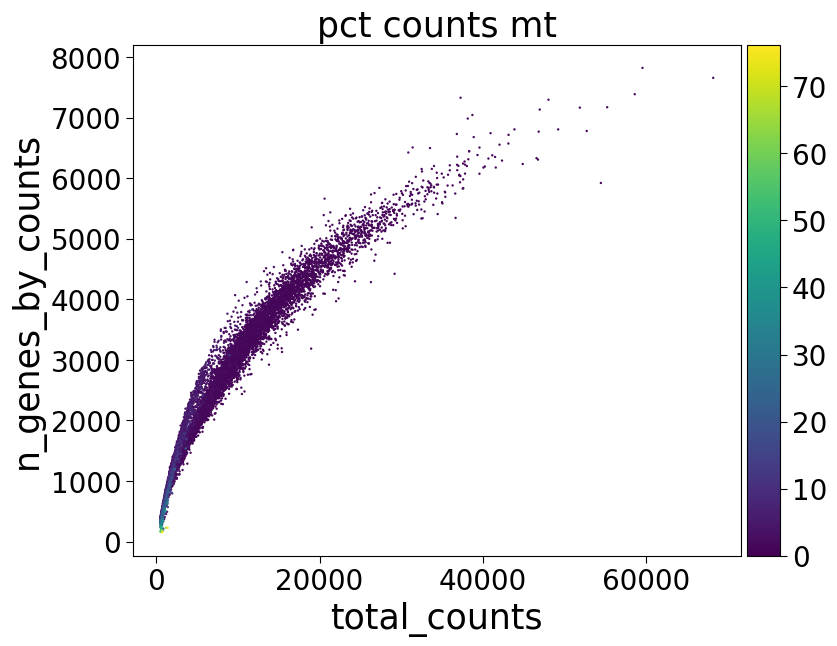

##### Lane: lane4 #####


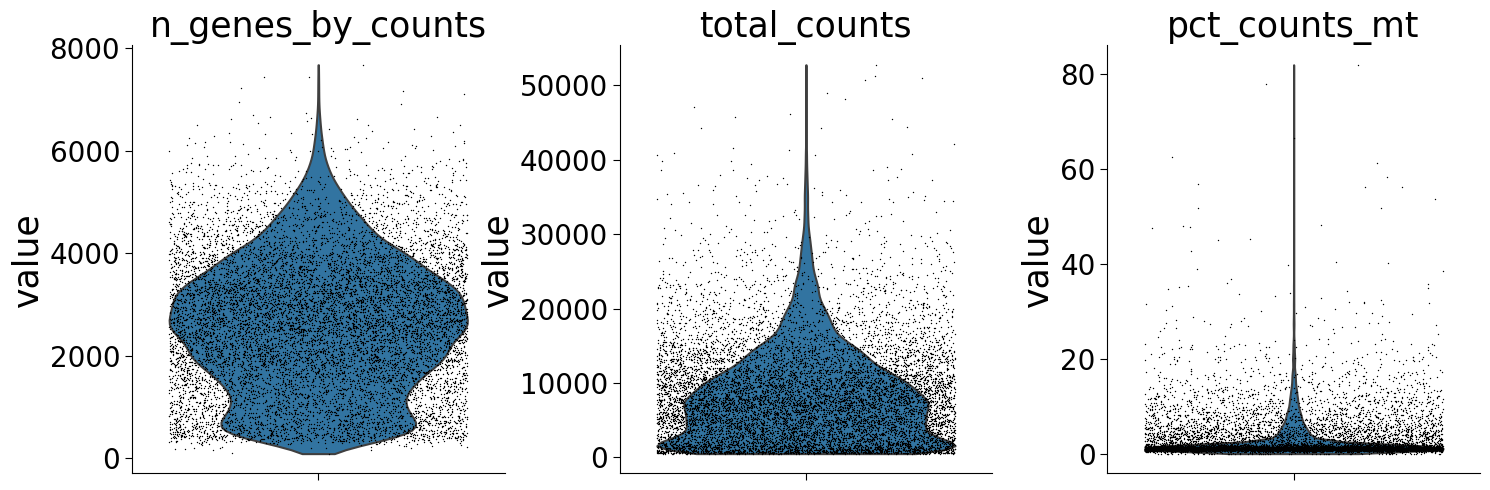

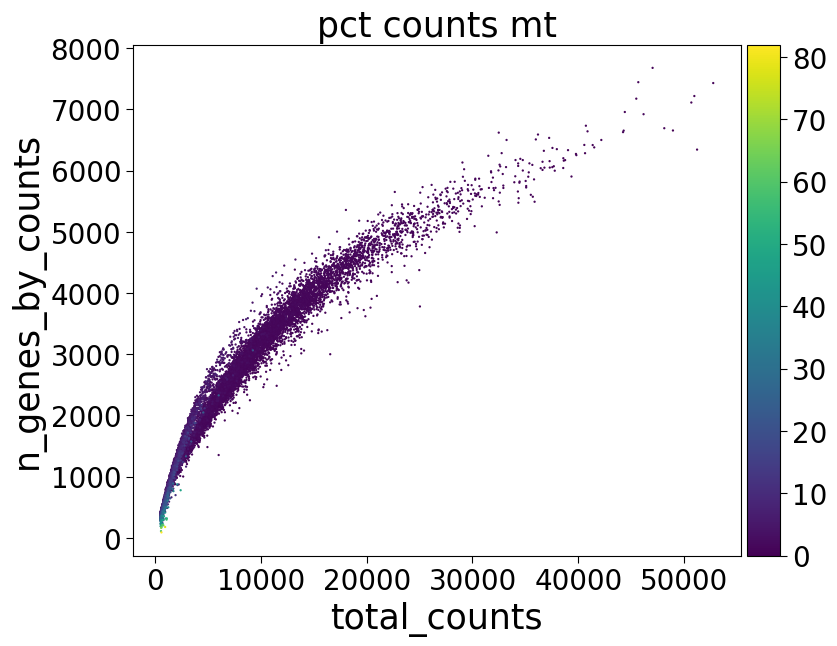

##### Lane: lane5 #####


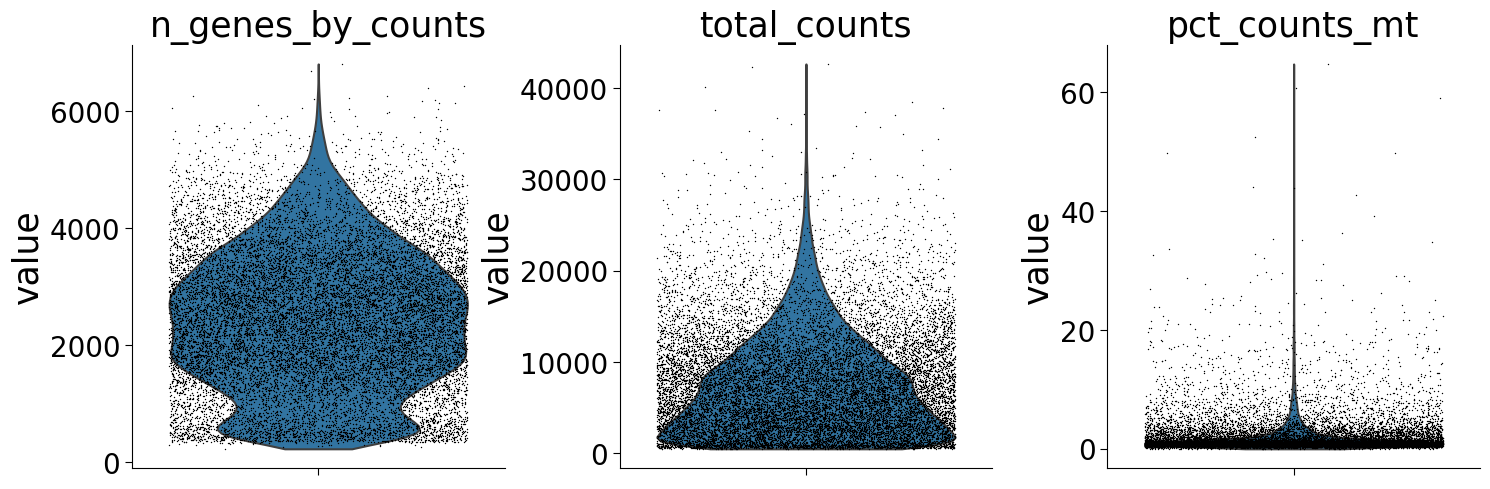

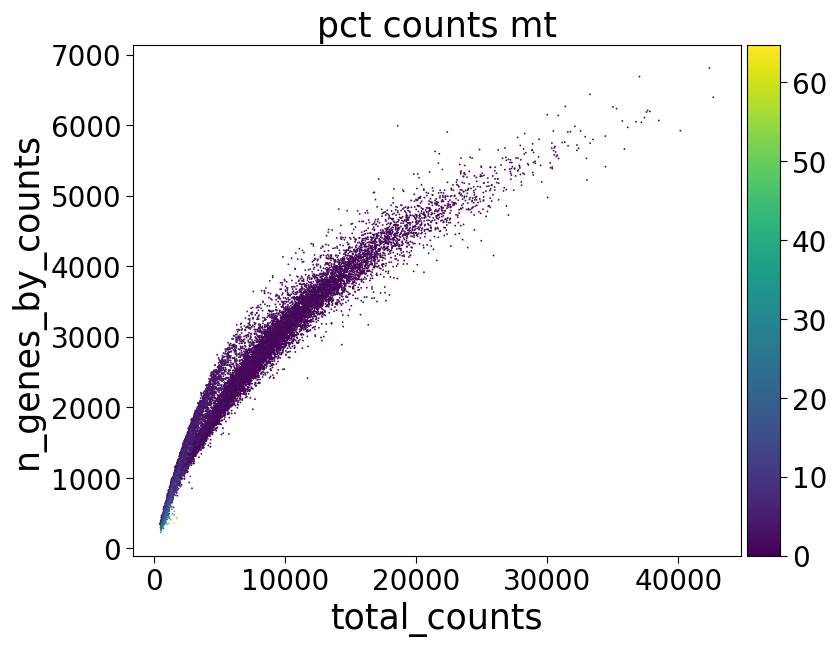

##### Lane: lane6 #####


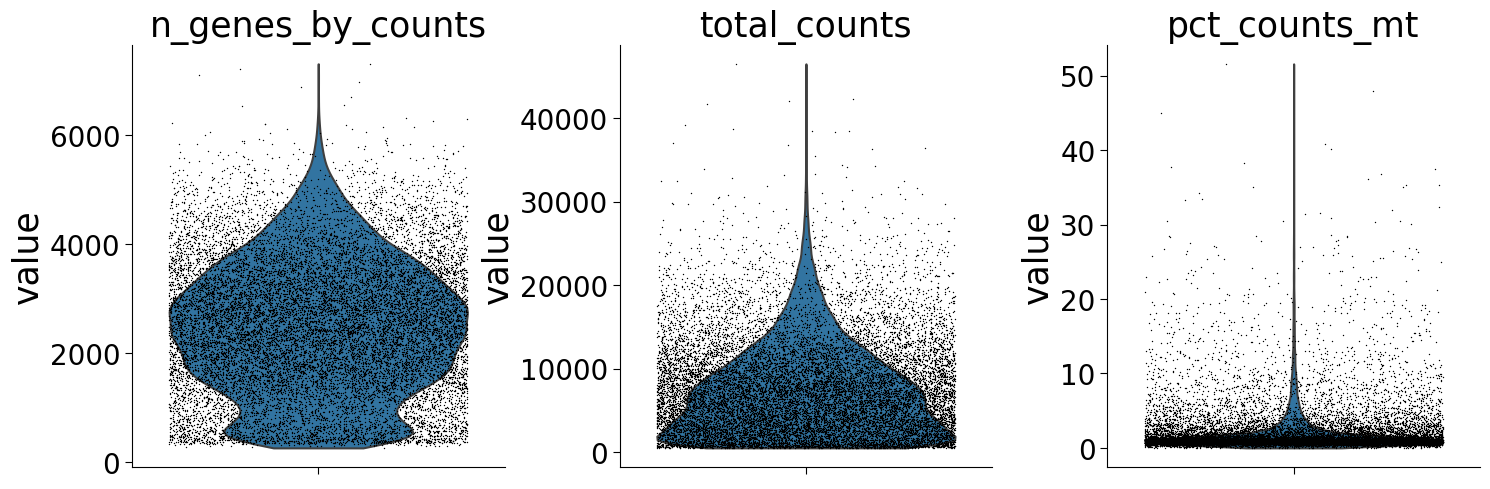

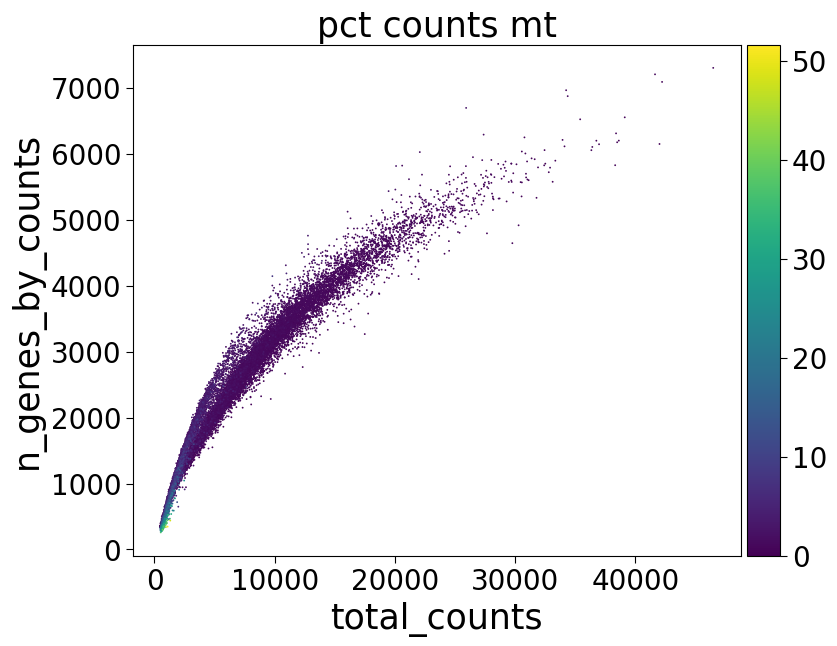

##### Lane: lane7 #####


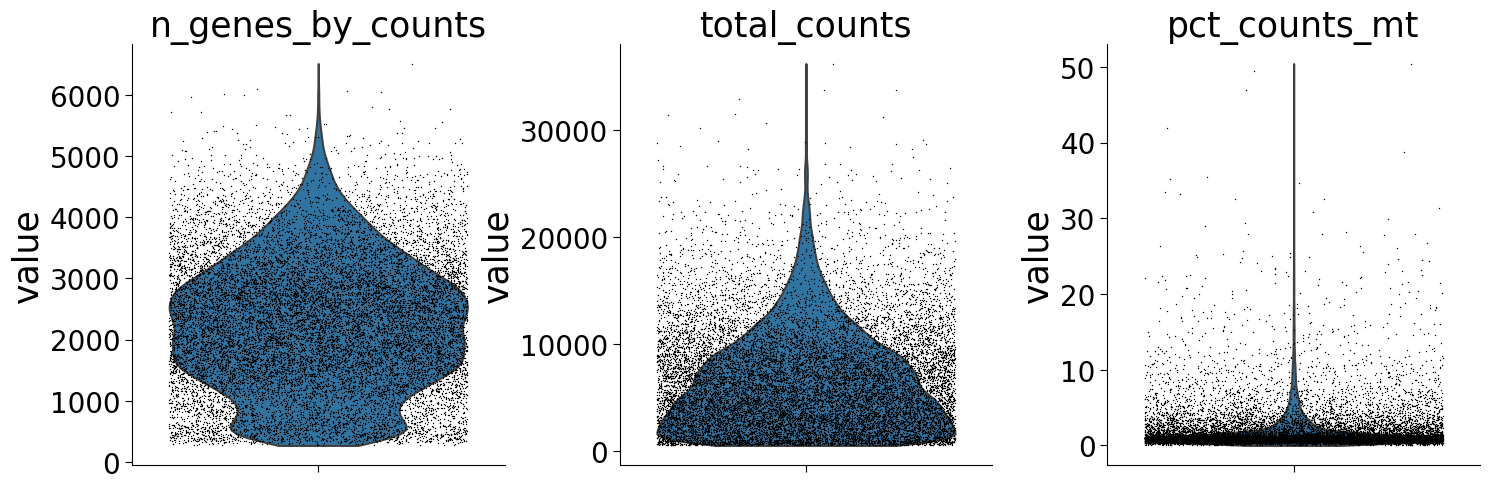

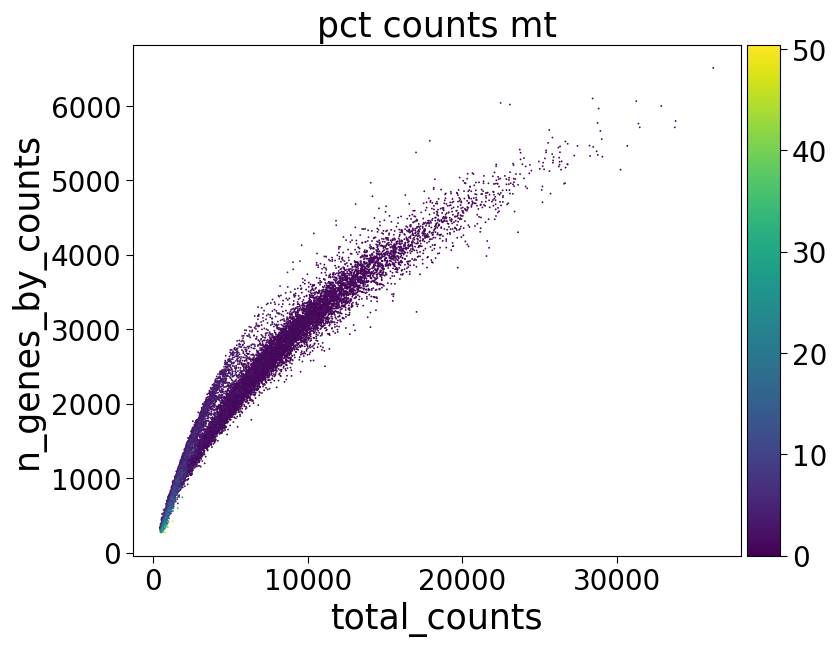

##### Lane: lane8 #####


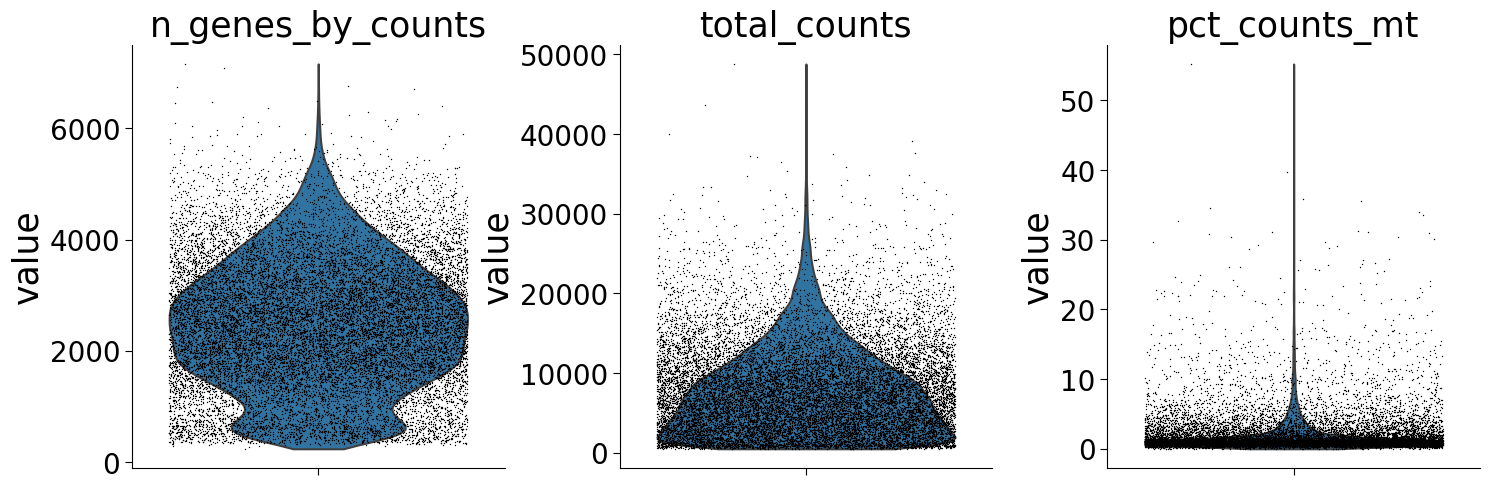

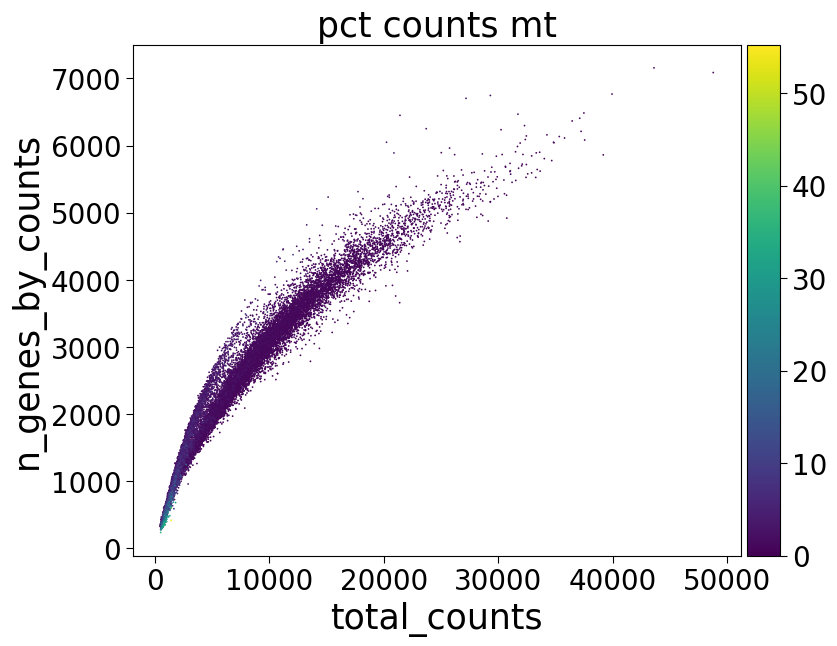

In [5]:
# 3) Run QC metrics (violin & scatter plots) for each lane
misc.plot_qc_metrics(adata_dict, qc_vars=["mt"])

In [6]:
# 3) Merge all AnnData objects into one
adata_list = list(adata_dict.values())

adata = adata_list[0].concatenate(
    *adata_list[1:], 
    batch_key="batch_lanes", 
    batch_categories=list(adata_dict.keys())
)

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/anndata/_core/anndata.py:1785: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  [AnnData(sparse.csr_matrix(a.shape), obs=a.obs) for a in all_adatas],


In [7]:
# Filter cells with less than 20% mitochondrial counts
adata = adata[adata.obs["percent_mito"] < 20, :]
    
sc.pp.filter_cells(adata, min_genes=400)
sc.pp.filter_genes(adata, min_cells=10)

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:140: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['n_genes'] = number


In [8]:
adata = misc.remove_TCR_genes(adata)

In [9]:
adata.obs = adata.obs[['lane', 'percent_mito']]
adata.var = adata.var[['gene_ids', 'feature_types']]

In [10]:
adata.obs_names = [e.split('-')[0] + '-1' for e in adata.obs_names]

In [11]:
# adata.write_h5ad('/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/01_combined.h5ad')

# Adding Metadata Variables

In [110]:
adata = sc.read_h5ad('/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/01_combined.h5ad')

## Mouse/Hashtag/Condition

In [111]:
import os
import pandas as pd

# Directory where the metadata CSV files are saved
metadata_directory = "/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/hashtag_metadata"

# Initialize a dictionary to store the metadata DataFrames
metadata_dfs = {}

# Loop through each file in the directory and read it into a DataFrame
for i in range(1, 9):
    file_path = os.path.join(metadata_directory, f"lane{i}_metadata.csv")
    metadata_dfs[f"lane{i}"] = pd.read_csv(file_path, index_col=0)

# Concatenate metadata DataFrames into one DataFrame
metadata_combined = pd.concat(metadata_dfs.values(), keys=metadata_dfs.keys())

# Reset the index and reformat it
metadata_combined = metadata_combined.reset_index()
metadata_combined.index = "lane" + metadata_combined['level_0'].apply(lambda e: e[4:]) + "_" + metadata_combined['level_1'].astype(str)
metadata_combined = metadata_combined.drop(columns=['level_0', 'level_1'])

In [115]:
metadata_combined

,orig.ident,nCount_RNA,nFeature_RNA,nCount_gRNA,nFeature_gRNA,nCount_HTO,nFeature_HTO,HTO_maxID,HTO_secondID,HTO_margin,HTO_classification,HTO_classification.global,hash.ID
lane1_AAACCTGAGAGATGAG-1,lane1,8984,2954,894,11,636,6,Hashtag5,Hashtag7,3.570044,Hashtag5,Singlet,Hashtag5
lane1_AAACCTGAGATATGCA-1,lane1,877,584,57,12,377,5,Hashtag5,Hashtag7,3.229864,Hashtag5,Singlet,Hashtag5
lane1_AAACCTGAGCAGGTCA-1,lane1,15916,4588,30,10,2285,6,Hashtag4,Hashtag7,4.029324,Hashtag4,Singlet,Hashtag4
lane1_AAACCTGAGCCACGTC-1,lane1,7948,3208,23,12,142,7,Hashtag5,Hashtag3,0.698383,Hashtag3_Hashtag5,Doublet,Doublet
lane1_AAACCTGAGTGGAGTC-1,lane1,14113,4085,1405,13,1179,7,Hashtag4,Hashtag6,0.352714,Hashtag4_Hashtag6,Doublet,Doublet
...,...,...,...,...,...,...,...,...,...,...,...,...,...
lane8_TTTGTCATCGGAAACG-1,lane8,9308,2913,23,11,487,8,Hashtag3,Hashtag8,2.227530,Hashtag3,Singlet,Hashtag3
lane8_TTTGTCATCGGTTCGG-1,lane8,3564,1545,47,14,867,8,Hashtag8,Hashtag2,2.002161,Hashtag2_Hashtag8,Doublet,Doublet
lane8_TTTGTCATCGTTGCCT-1,lane8,8433,2834,2609,9,815,8,Hashtag2,Hashtag8,2.987494,Hashtag2,Singlet,Hashtag2
lane8_TTTGTCATCTCAAGTG-1,lane8,4970,1969,36,11,328,8,Hashtag3,Hashtag8,1.852338,Hashtag3,Singlet,Hashtag3


In [116]:
adata.obs = adata.obs.join(metadata_combined[['HTO_classification.global', 'HTO_maxID']], how='left')

In [117]:
adata = adata[adata.obs['HTO_classification.global'] == 'Singlet']

adata.obs.rename(columns={'HTO_maxID':'hashtag'}, inplace=True)

In [118]:
def get_condition(lane):
    if lane in ['lane1', 'lane2', 'lane3', 'lane4']:
        return 'Isotype'
    else:
        return 'PD1'

def get_hashtag(CBC):
    return int(CBC_hashtag_dict[CBC][-1])

In [119]:
adata.obs['condition'] = adata.obs['lane'].apply(get_condition)
adata.obs['hashtag_number'] = adata.obs['hashtag'].str.extract('(\d+)').astype(int)

adata.obs['mouse'] = adata.obs.apply(lambda r: f"{r['condition']}_{r['hashtag']}", axis=1)
mouse_vc = adata.obs['mouse'].value_counts()

/tmp/ipykernel_2943178/3270858648.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['condition'] = adata.obs['lane'].apply(get_condition)


## all_constructs_str

In [121]:
reload(clonal_processing)
import clonal_processing

lane_info = []
for i in range(1, 9):
    lane_info.append({
        'lane_id': f'lane{i}',
        'assigned_bam_file': f"/Genomics/pritykinlab/share/perturbseq/fromMarc/new_data/exp49_CP8_old/pycashier/lane{i}/assigned_sorted.bam",
        'umi_file': f"/Genomics/pritykinlab/share/perturbseq/fromMarc/new_data/exp49_CP8_old/pycashier/lane{i}/read_UMI.tsv"
    })

guide_seq_csv = "/Genomics/pritykinlab/share/perturbseq/fromMarc/new_data/exp49_CP8_old/guide_seq_info.csv"
output_all_path = "/Genomics/pritykinlab/share/perturbseq/fromMarc/new_data/exp49_CP8_old/pycashier/CBC_guide_umi.tsv"

guide_umi_df = clonal_processing.build_guide_umi_df_for_all_lanes(
    lane_info=lane_info,
    guide_seq_csv=guide_seq_csv,
    output_all_path=output_all_path,
    overwrite=False
)

cbc_construct_mtx = clonal_processing.pivot_CBC_construct_mtx(
    guide_umi_df,
    min_count=10,   # or another threshold
    binarize=False
)

clonal_processing.annotate_adata_with_clones(
    adata,
    cbc_construct_mtx
)

In [122]:
cbc_construct_mtx

construct,Bach2-1__AAACCC,Bach2-1__AACACA,Bach2-1__AACCCC,Bach2-1__AACGCC,Bach2-1__AACTGC,Bach2-1__AAGACG,Bach2-1__AAGCGG,Bach2-1__AAGGTG,Bach2-1__AATATA,Bach2-1__ACAATG,...,Trim28-2__TGGCGG,Trim28-2__TGTAAA,Trim28-2__TGTCCT,Trim28-2__TTACCA,Trim28-2__TTACCC,Trim28-2__TTCAAA,Trim28-2__TTCAAC,Trim28-2__TTCCAC,Trim28-2__TTCCCC,Trim28-2__TTGCAC
CBC,,,,,,,,,,,,,,,,,,,,,
lane1_AAACCTGAGAGATGAG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
lane1_AAACCTGAGATATGCA-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
lane1_AAACCTGAGGACGAAA-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
lane1_AAACCTGAGTGGAGTC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
lane1_AAACCTGCAAGTAGTA-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
lane8_TTTGTCATCCTGCAGG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
lane8_TTTGTCATCGCGTAGC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
lane8_TTTGTCATCGTTGCCT-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## doublet construct calling

In [123]:
adata = clonal_processing.run_doublet_constrct_calling(adata)

# Get some useful columns

In [124]:
def get_cat_num_constructs(e):
    if e == 1:
        return "One"
    elif e > 1:
        return "More than One"
    else:
        return "Zero"
adata.obs['cat_num_constructs'] = adata.obs['num_constructs'].apply(get_cat_num_constructs)

def assign_clone(row):
    if row['all_constructs_str'] == '':
        return ''
    else:
        return f"{row['mouse']}|{row['all_constructs_str']}"
    
# Helper function to process guides and perturbations
def process_constructs(row):
    value = row['all_constructs_str']
    guides = value.split('___')
    processed_guides = []
    processed_perturbations = []
    for guide in guides:
        split_guide = guide.split('__')
        processed_guides.append(split_guide[0])
        if guide.startswith("ONE_INTERGENIC_SITE_") or guide.startswith("NO_SITE_"):
            processed_perturbations.append("NT")
        else:
            gene = split_guide[0].split('-')[0]
            processed_perturbations.append(gene)
    return "__".join(processed_guides), "__".join(processed_perturbations)

# Apply the function row-wise and create new columns
adata.obs[['guide', 'perturbation']] = adata.obs.apply(process_constructs, axis=1, result_type='expand')

# Apply the function across the rows
adata.obs['clone'] = adata.obs.apply(assign_clone, axis=1)

In [125]:
from collections import OrderedDict

guide_new_label_mapping = OrderedDict([
    ('ONE_INTERGENIC_SITE_18', 'INTERGENIC-5'),
    ('NO_SITE_26', 'NO_SITE-1'),
    ('NO_SITE_80', 'NO_SITE-2'),
    ('NO_SITE_223', 'NO_SITE-3'),
    ('NO_SITE_913', 'NO_SITE-4'),
    ('NO_SITE_738', 'NO_SITE-5'),
    ('ONE_INTERGENIC_SITE_1', 'INTERGENIC-1'),
    ('ONE_INTERGENIC_SITE_21', 'INTERGENIC-2'),
    ('ONE_INTERGENIC_SITE_5', 'INTERGENIC-3'),
    ('ONE_INTERGENIC_SITE_24', 'INTERGENIC-4'),
    ('NO_SITE_5', 'NO_SITE-6'),
    ('NO_SITE_3', 'NO_SITE-7'),
    ('NO_SITE_1', 'NO_SITE-8'),
    ('NO_SITE_2', 'NO_SITE-9'),
    ('NO_SITE_4', 'NO_SITE-10'),
    ('NO_SITE_6', 'NO_SITE-11'),
])

columns_to_change = ['all_constructs_str', 'guide']
for col in columns_to_change:
    for key, value in guide_new_label_mapping.items():
        adata.obs[col] = adata.obs[col].apply(lambda e: e.replace(key, value))

In [126]:
adata.write_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/02_LP.h5ad")